In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
df=pd.read_csv('csv/patient_admissions.csv')

In [16]:
recovery_df=pd.read_csv('csv/patient_recovery.csv')

In [17]:
df.shape
df.size

88

In [21]:
df.isna().sum()

Patient_ID        0
Department        0
Stay_Days         0
Treatment_Cost    0
dtype: int64

In [19]:
df.fillna({'Stay_Days':df['Stay_Days'].mean(),'Treatment_Cost':df['Treatment_Cost'].mean()},inplace=True)

,Patient_ID,Department,Stay_Days,Treatment_Cost
0,P201,Cardiology,4.0,1200.000000
1,P202,Neurology,6.0,1800.000000
2,P203,Orthopaedics,3.0,950.000000
3,P204,Cardiology,5.0,1500.000000
4,P205,Neurology,2.0,700.000000
5,P206,Paediatrics,4.0,1100.000000
6,P207,Orthopaedics,7.0,2100.000000
7,P208,Cardiology,4.6,1300.000000
8,P209,Paediatrics,3.0,900.000000
9,P210,Neurology,5.0,1600.000000


In [20]:
# df['Stay_Days'].fillna(df['Stay_Days'].mean(),inplace=True)
# df['Treatment_Cost'].fillna(df['Treatment_Cost'].mean(),inplace=True)

In [23]:
df.duplicated().sum()

np.int64(2)

In [26]:
df.drop_duplicates(inplace=True,keep='first')

In [27]:
merged=df.merge(recovery_df,on='Patient_ID',how='inner')

In [28]:
merged.head()

,Patient_ID,Department,Stay_Days,Treatment_Cost,Recovery_Score
0,P201,Cardiology,4.0,1200.0,82.0
1,P202,Neurology,6.0,1800.0,75.0
2,P203,Orthopaedics,3.0,950.0,68.0
3,P204,Cardiology,5.0,1500.0,88.0
4,P205,Neurology,2.0,700.0,79.0


In [42]:
df.boxplot(by='Department',column='Treatment_Cost',grid=True)
plt.suptitle('')
plt.title('Box plot')

Text(0.5, 1.0, 'Box plot')

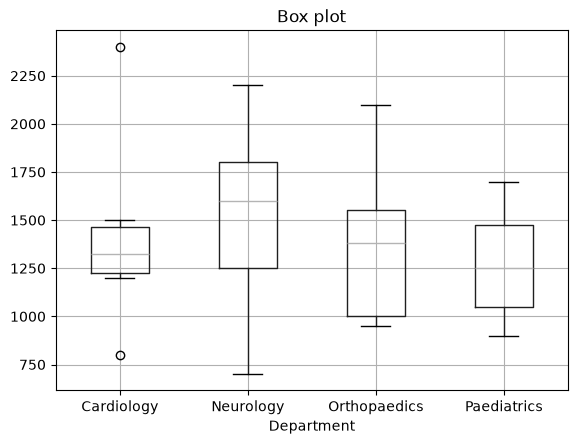

In [43]:
plt.show()

In [44]:
import sqlite3

In [46]:
conn=sqlite3.connect('Hospital.db')

In [47]:
cursor=conn.cursor()

In [48]:
merged.to_sql("Hospital",
       con=conn,
       schema=None,
       if_exists='replace')

20

In [51]:
cursor.execute("""select * from Hospital""")

In [52]:
cursor.fetchall()

[(0, 'P201', 'Cardiology', 4.0, 1200.0, 82.0),
 (1, 'P202', 'Neurology', 6.0, 1800.0, 75.0),
 (2, 'P203', 'Orthopaedics', 3.0, 950.0, 68.0),
 (3, 'P204', 'Cardiology', 5.0, 1500.0, 88.0),
 (4, 'P205', 'Neurology', 2.0, 700.0, 79.0),
 (5, 'P206', 'Paediatrics', 4.0, 1100.0, 91.0),
 (6, 'P207', 'Orthopaedics', 7.0, 2100.0, 72.0),
 (7, 'P208', 'Cardiology', 4.6, 1300.0, 85.0),
 (8, 'P209', 'Paediatrics', 3.0, 900.0, 94.0),
 (9, 'P210', 'Neurology', 5.0, 1600.0, 77.0),
 (10, 'P211', 'Cardiology', 2.0, 800.0, 81.0),
 (11, 'P212', 'Orthopaedics', 6.0, 1383.3333333333333, 70.0),
 (12, 'P213', 'Paediatrics', 5.0, 1400.0, 89.0),
 (13, 'P214', 'Neurology', 4.0, 1250.0, 83.0),
 (14, 'P215', 'Cardiology', 8.0, 2400.0, 65.0),
 (15, 'P216', 'Orthopaedics', 3.0, 1000.0, 87.0),
 (16, 'P217', 'Paediatrics', 6.0, 1700.0, 92.0),
 (17, 'P218', 'Neurology', 7.0, 2200.0, 74.0),
 (18, 'P219', 'Cardiology', 4.0, 1350.0, None),
 (19, 'P220', 'Orthopaedics', 5.0, 1550.0, 80.0)]

In [54]:
len(merged)

20

In [55]:
cursor.execute("""select count(*) from Hospital""")

In [56]:
cursor.fetchall()

[(20,)]

In [58]:
selected_department="Cardiology"

In [62]:
cursor.execute("""select * from Hospital where Department=?""",(selected_department,))

In [63]:
cursor.fetchall()

[(0, 'P201', 'Cardiology', 4.0, 1200.0, 82.0),
 (3, 'P204', 'Cardiology', 5.0, 1500.0, 88.0),
 (7, 'P208', 'Cardiology', 4.6, 1300.0, 85.0),
 (10, 'P211', 'Cardiology', 2.0, 800.0, 81.0),
 (14, 'P215', 'Cardiology', 8.0, 2400.0, 65.0),
 (18, 'P219', 'Cardiology', 4.0, 1350.0, None)]

In [64]:
cursor.execute("""update Hospital set Recovery_Score= ? where Patient_ID=?""",(85,"P205",))

In [65]:
cursor.execute("select * from Hospital")

In [66]:
cursor.fetchall()

[(0, 'P201', 'Cardiology', 4.0, 1200.0, 82.0),
 (1, 'P202', 'Neurology', 6.0, 1800.0, 75.0),
 (2, 'P203', 'Orthopaedics', 3.0, 950.0, 68.0),
 (3, 'P204', 'Cardiology', 5.0, 1500.0, 88.0),
 (4, 'P205', 'Neurology', 2.0, 700.0, 85.0),
 (5, 'P206', 'Paediatrics', 4.0, 1100.0, 91.0),
 (6, 'P207', 'Orthopaedics', 7.0, 2100.0, 72.0),
 (7, 'P208', 'Cardiology', 4.6, 1300.0, 85.0),
 (8, 'P209', 'Paediatrics', 3.0, 900.0, 94.0),
 (9, 'P210', 'Neurology', 5.0, 1600.0, 77.0),
 (10, 'P211', 'Cardiology', 2.0, 800.0, 81.0),
 (11, 'P212', 'Orthopaedics', 6.0, 1383.3333333333333, 70.0),
 (12, 'P213', 'Paediatrics', 5.0, 1400.0, 89.0),
 (13, 'P214', 'Neurology', 4.0, 1250.0, 83.0),
 (14, 'P215', 'Cardiology', 8.0, 2400.0, 65.0),
 (15, 'P216', 'Orthopaedics', 3.0, 1000.0, 87.0),
 (16, 'P217', 'Paediatrics', 6.0, 1700.0, 92.0),
 (17, 'P218', 'Neurology', 7.0, 2200.0, 74.0),
 (18, 'P219', 'Cardiology', 4.0, 1350.0, None),
 (19, 'P220', 'Orthopaedics', 5.0, 1550.0, 80.0)]

In [71]:
recovery_score=cursor.execute("""select Patient_ID,Department,Recovery_Score from Hospital where Recovery_Score>=80 order by Recovery_Score Desc""")

In [72]:
cursor.fetchall()

[('P209', 'Paediatrics', 94.0),
 ('P217', 'Paediatrics', 92.0),
 ('P206', 'Paediatrics', 91.0),
 ('P213', 'Paediatrics', 89.0),
 ('P204', 'Cardiology', 88.0),
 ('P216', 'Orthopaedics', 87.0),
 ('P205', 'Neurology', 85.0),
 ('P208', 'Cardiology', 85.0),
 ('P214', 'Neurology', 83.0),
 ('P201', 'Cardiology', 82.0),
 ('P211', 'Cardiology', 81.0),
 ('P220', 'Orthopaedics', 80.0)]

In [74]:
recovery=pd.read_sql_query("""select Patient_ID,Department,Recovery_Score from Hospital where Recovery_Score>=80 order by Recovery_Score Desc""",
                           conn)


In [75]:
recovery.to_csv('recovered.csv',index=False)

In [80]:
import torch.nn as nn

In [78]:
import torch.optim as optim

In [81]:
class RecoveryNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1=nn.Linear(5,10)
        self.fc2=nn.Linear(10,5)
        self.fc3=nn.Linear(5,1)
        self.relu=nn.ReLU()

    def forward(self,x):
        x=self.relu(self.fc1(x))
        x=self.relu(self.fc2(x))
        x=self.relu(self.fc3(x))

        return x


model=RecoveryNet()

criterion=nn.MSELoss()
optimizer=optim.Adam(model.parameters(),lr=0.01)

    

In [102]:
class RecoveryNet(nn.Module):
    def __init__(self):
        super(RecoveryNet,self).__init__()

        self.network=nn.Sequential(
            nn.Linear(5,10),
            nn.ReLU(),
            nn.Linear(10,5),
            nn.ReLU(),
            nn.Linear(5,1)
        )

    def forward(self,x):
        return self.network(x)



model=RecoveryNet()

criterion=nn.MSELoss()
optimizer=optim.Adam(model.parameters(),lr=0.05)


In [103]:
x=torch.randn(150,5) # 150 data samples,5 features

In [104]:
x.shape

torch.Size([150, 5])

In [105]:
w=torch.randn(5,1)


In [106]:
y=x@w+2+torch.randn(150,1)*0.1

In [107]:
losses=[]
for epoch in range(20):
    prediction=model(x)
    optimizer.zero_grad()
    loss=criterion(prediction, y)
    losses.append(loss)
    loss.backward()
    optimizer.step()
    print(f"epoch is {epoch} and loss is {loss}")



epoch is 0 and loss is 10.135489463806152
epoch is 1 and loss is 9.488333702087402
epoch is 2 and loss is 8.759856224060059
epoch is 3 and loss is 7.661457538604736
epoch is 4 and loss is 6.260929107666016
epoch is 5 and loss is 4.766050815582275
epoch is 6 and loss is 3.495854139328003
epoch is 7 and loss is 2.948305130004883
epoch is 8 and loss is 3.0683064460754395
epoch is 9 and loss is 2.8165695667266846
epoch is 10 and loss is 2.0715878009796143
epoch is 11 and loss is 1.2944955825805664
epoch is 12 and loss is 0.8114954829216003
epoch is 13 and loss is 0.6750512719154358
epoch is 14 and loss is 0.7218702435493469
epoch is 15 and loss is 0.8272245526313782
epoch is 16 and loss is 0.9276418089866638
epoch is 17 and loss is 0.9615089893341064
epoch is 18 and loss is 0.9427303075790405
epoch is 19 and loss is 0.8569762110710144


In [108]:
def predict(x):
    model.eval()
    with torch.no_grad():
        prediction=model(x)

    return prediction

In [114]:
x=torch.Tensor([3,4,5,1,2])
res=predict(x)
print(res)

tensor([-4.5742])
